# 1. Setup and Imports

In [9]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

import utils
import heapq
from road_network_graph import RoadNetworkGraph

print("All imports successful!")

All imports successful!


# 2. Mock data

In [10]:
print("Loading ENHANCED Bucharest pollution data...\n")

# Enhanced data with 65+ points creating complex pollution landscape
bucharest_pollution_data = [
    # ========== EXTREME POLLUTION BARRIER - Central Traffic Wall ==========
    {'lat': 44.4268, 'lon': 26.1025, 'pm10': 75.0, 'pm25': 42.0, 'no2': 85.0},  # Unirii
    {'lat': 44.4268, 'lon': 26.1050, 'pm10': 78.0, 'pm25': 44.0, 'no2': 88.0},
    {'lat': 44.4268, 'lon': 26.1075, 'pm10': 76.0, 'pm25': 43.0, 'no2': 86.0},
    {'lat': 44.4268, 'lon': 26.1100, 'pm10': 77.0, 'pm25': 43.5, 'no2': 87.0},
    {'lat': 44.4268, 'lon': 26.1125, 'pm10': 75.5, 'pm25': 42.5, 'no2': 85.5},
    
    # ========== VERY HIGH POLLUTION - Major Intersections ==========
    {'lat': 44.4358, 'lon': 26.1028, 'pm10': 68.0, 'pm25': 38.0, 'no2': 72.0},  # Romana
    {'lat': 44.4478, 'lon': 26.0975, 'pm10': 70.0, 'pm25': 40.0, 'no2': 74.0},  # Victoriei
    {'lat': 44.4100, 'lon': 26.1200, 'pm10': 69.0, 'pm25': 39.0, 'no2': 73.0},
    {'lat': 44.4020, 'lon': 26.0850, 'pm10': 71.0, 'pm25': 40.5, 'no2': 75.0},  # Progresul
    {'lat': 44.4200, 'lon': 26.1025, 'pm10': 67.0, 'pm25': 37.5, 'no2': 71.0},
    
    # ========== HIGH POLLUTION - X Pattern Roads ==========
    # First diagonal
    {'lat': 44.4400, 'lon': 26.0900, 'pm10': 58.0, 'pm25': 32.0, 'no2': 62.0},
    {'lat': 44.4350, 'lon': 26.0950, 'pm10': 59.0, 'pm25': 32.5, 'no2': 63.0},
    {'lat': 44.4300, 'lon': 26.1000, 'pm10': 60.0, 'pm25': 33.0, 'no2': 64.0},
    {'lat': 44.4250, 'lon': 26.1050, 'pm10': 61.0, 'pm25': 33.5, 'no2': 65.0},
    {'lat': 44.4200, 'lon': 26.1100, 'pm10': 59.5, 'pm25': 32.8, 'no2': 63.5},
    {'lat': 44.4150, 'lon': 26.1150, 'pm10': 58.5, 'pm25': 32.2, 'no2': 62.5},
    
    # Second diagonal
    {'lat': 44.4400, 'lon': 26.1150, 'pm10': 57.0, 'pm25': 31.5, 'no2': 61.0},
    {'lat': 44.4350, 'lon': 26.1100, 'pm10': 58.0, 'pm25': 32.0, 'no2': 62.0},
    {'lat': 44.4300, 'lon': 26.1050, 'pm10': 59.0, 'pm25': 32.5, 'no2': 63.0},
    {'lat': 44.4250, 'lon': 26.1000, 'pm10': 60.0, 'pm25': 33.0, 'no2': 64.0},
    {'lat': 44.4200, 'lon': 26.0950, 'pm10': 58.5, 'pm25': 32.2, 'no2': 62.5},
    
    # ========== MEDIUM-HIGH - Ring Around Center ==========
    # North ring
    {'lat': 44.4380, 'lon': 26.0800, 'pm10': 48.0, 'pm25': 26.0, 'no2': 52.0},
    {'lat': 44.4420, 'lon': 26.0820, 'pm10': 47.0, 'pm25': 25.5, 'no2': 51.0},
    {'lat': 44.4460, 'lon': 26.0850, 'pm10': 46.0, 'pm25': 25.0, 'no2': 50.0},
    {'lat': 44.4500, 'lon': 26.0900, 'pm10': 47.5, 'pm25': 26.0, 'no2': 51.5},
    {'lat': 44.4520, 'lon': 26.0950, 'pm10': 48.5, 'pm25': 26.5, 'no2': 52.5},
    {'lat': 44.4520, 'lon': 26.1050, 'pm10': 49.0, 'pm25': 27.0, 'no2': 53.0},
    {'lat': 44.4500, 'lon': 26.1150, 'pm10': 47.0, 'pm25': 25.5, 'no2': 51.0},
    {'lat': 44.4450, 'lon': 26.1200, 'pm10': 46.0, 'pm25': 25.0, 'no2': 50.0},
    {'lat': 44.4400, 'lon': 26.1250, 'pm10': 48.0, 'pm25': 26.0, 'no2': 52.0},
    
    # South ring
    {'lat': 44.4150, 'lon': 26.0850, 'pm10': 49.0, 'pm25': 27.0, 'no2': 53.0},
    {'lat': 44.4100, 'lon': 26.0900, 'pm10': 48.0, 'pm25': 26.0, 'no2': 52.0},
    {'lat': 44.4050, 'lon': 26.0950, 'pm10': 47.0, 'pm25': 25.5, 'no2': 51.0},
    {'lat': 44.4050, 'lon': 26.1050, 'pm10': 48.5, 'pm25': 26.5, 'no2': 52.5},
    {'lat': 44.4100, 'lon': 26.1100, 'pm10': 49.0, 'pm25': 27.0, 'no2': 53.0},
    {'lat': 44.4150, 'lon': 26.1150, 'pm10': 48.0, 'pm25': 26.0, 'no2': 52.0},
    
    # ========== MEDIUM POLLUTION - Buffer Zones ==========
    # North buffer
    {'lat': 44.4550, 'lon': 26.0750, 'pm10': 38.0, 'pm25': 21.0, 'no2': 42.0},
    {'lat': 44.4580, 'lon': 26.0800, 'pm10': 37.0, 'pm25': 20.5, 'no2': 41.0},
    {'lat': 44.4600, 'lon': 26.0850, 'pm10': 36.0, 'pm25': 20.0, 'no2': 40.0},  # Aviatorilor
    {'lat': 44.4600, 'lon': 26.1050, 'pm10': 37.5, 'pm25': 20.8, 'no2': 41.5},
    {'lat': 44.4580, 'lon': 26.1200, 'pm10': 38.0, 'pm25': 21.0, 'no2': 42.0},
    {'lat': 44.4550, 'lon': 26.1300, 'pm10': 36.5, 'pm25': 20.3, 'no2': 40.5},
    
    # South buffer
    {'lat': 44.4000, 'lon': 26.0800, 'pm10': 39.0, 'pm25': 21.5, 'no2': 43.0},
    {'lat': 44.3980, 'lon': 26.0900, 'pm10': 38.0, 'pm25': 21.0, 'no2': 42.0},
    {'lat': 44.3950, 'lon': 26.1000, 'pm10': 37.0, 'pm25': 20.5, 'no2': 41.0},
    {'lat': 44.3980, 'lon': 26.1100, 'pm10': 38.5, 'pm25': 21.3, 'no2': 42.5},
    {'lat': 44.4000, 'lon': 26.1200, 'pm10': 39.0, 'pm25': 21.5, 'no2': 43.0},
    
    # East buffer
    {'lat': 44.4350, 'lon': 26.1250, 'pm10': 38.0, 'pm25': 21.0, 'no2': 42.0},  # Obor
    {'lat': 44.4450, 'lon': 26.1400, 'pm10': 35.0, 'pm25': 19.0, 'no2': 38.0},  # Colentina
    {'lat': 44.4150, 'lon': 26.1450, 'pm10': 34.0, 'pm25': 18.5, 'no2': 36.0},  # Pantelimon
    {'lat': 44.4100, 'lon': 26.1300, 'pm10': 37.0, 'pm25': 20.5, 'no2': 41.0},  # Titan
    
    # West buffer
    {'lat': 44.4320, 'lon': 26.0580, 'pm10': 35.0, 'pm25': 19.5, 'no2': 39.0},  # Cotroceni
    {'lat': 44.4367, 'lon': 26.0897, 'pm10': 36.0, 'pm25': 20.0, 'no2': 40.0},  # Cismigiu
    {'lat': 44.4350, 'lon': 26.0450, 'pm10': 34.0, 'pm25': 19.0, 'no2': 38.0},  # Militari
    
    # ========== LOW POLLUTION - Clean Corridors ==========
    # North corridor (clean paths)
    {'lat': 44.4650, 'lon': 26.0850, 'pm10': 24.0, 'pm25': 14.0, 'no2': 22.0},  # Herastrau
    {'lat': 44.4680, 'lon': 26.0900, 'pm10': 23.0, 'pm25': 13.5, 'no2': 21.0},
    {'lat': 44.4700, 'lon': 26.0950, 'pm10': 22.0, 'pm25': 13.0, 'no2': 20.0},
    {'lat': 44.4720, 'lon': 26.1000, 'pm10': 23.5, 'pm25': 13.8, 'no2': 21.5},
    {'lat': 44.4720, 'lon': 26.1100, 'pm10': 24.0, 'pm25': 14.0, 'no2': 22.0},
    {'lat': 44.4700, 'lon': 26.1200, 'pm10': 23.0, 'pm25': 13.5, 'no2': 21.0},
    {'lat': 44.4650, 'lon': 26.1300, 'pm10': 25.0, 'pm25': 14.5, 'no2': 23.0},
    
    # West corridor (clean)
    {'lat': 44.4500, 'lon': 26.0650, 'pm10': 26.0, 'pm25': 15.0, 'no2': 24.0},
    {'lat': 44.4420, 'lon': 26.0650, 'pm10': 25.0, 'pm25': 14.5, 'no2': 23.0},
    {'lat': 44.4350, 'lon': 26.0650, 'pm10': 27.0, 'pm25': 15.5, 'no2': 25.0},
    {'lat': 44.4250, 'lon': 26.0680, 'pm10': 28.0, 'pm25': 16.0, 'no2': 26.0},
    
    # East corridor (clean)
    {'lat': 44.4500, 'lon': 26.1400, 'pm10': 27.0, 'pm25': 15.5, 'no2': 25.0},
    {'lat': 44.4420, 'lon': 26.1420, 'pm10': 26.0, 'pm25': 15.0, 'no2': 24.0},
    {'lat': 44.4350, 'lon': 26.1450, 'pm10': 28.0, 'pm25': 16.0, 'no2': 26.0},
    {'lat': 44.4250, 'lon': 26.1400, 'pm10': 27.5, 'pm25': 15.8, 'no2': 25.5},
    
    # ========== VERY LOW POLLUTION - Outer Edges ==========
    {'lat': 44.4780, 'lon': 26.0650, 'pm10': 20.0, 'pm25': 12.0, 'no2': 18.0},  # Baneasa
    {'lat': 44.4800, 'lon': 26.0850, 'pm10': 19.0, 'pm25': 11.5, 'no2': 17.0},
    {'lat': 44.4820, 'lon': 26.1050, 'pm10': 21.0, 'pm25': 12.5, 'no2': 19.0},
    {'lat': 44.4800, 'lon': 26.1250, 'pm10': 20.5, 'pm25': 12.3, 'no2': 18.5},
    {'lat': 44.4850, 'lon': 26.1300, 'pm10': 20.0, 'pm25': 12.0, 'no2': 18.0},  # Pipera
    
    {'lat': 44.3900, 'lon': 26.0600, 'pm10': 21.0, 'pm25': 12.5, 'no2': 19.0},
    {'lat': 44.3880, 'lon': 26.0850, 'pm10': 20.0, 'pm25': 12.0, 'no2': 18.0},
    {'lat': 44.3850, 'lon': 26.1050, 'pm10': 22.0, 'pm25': 13.0, 'no2': 20.0},
    {'lat': 44.3880, 'lon': 26.1250, 'pm10': 21.5, 'pm25': 12.8, 'no2': 19.5},
    {'lat': 44.3900, 'lon': 26.1450, 'pm10': 20.0, 'pm25': 12.0, 'no2': 18.0},
    {'lat': 44.3950, 'lon': 26.1050, 'pm10': 20.0, 'pm25': 12.0, 'no2': 18.0},  # Berceni

    # More detailed North-South corridor
    {'lat': 44.4650, 'lon': 26.0900, 'pm10': 23.5, 'pm25': 13.8, 'no2': 21.5},
    {'lat': 44.4650, 'lon': 26.0950, 'pm10': 24.5, 'pm25': 14.3, 'no2': 22.5},
    {'lat': 44.4650, 'lon': 26.1000, 'pm10': 25.0, 'pm25': 14.5, 'no2': 23.0},
    {'lat': 44.4650, 'lon': 26.1050, 'pm10': 24.0, 'pm25': 14.0, 'no2': 22.0},
    {'lat': 44.4650, 'lon': 26.1100, 'pm10': 25.5, 'pm25': 14.8, 'no2': 23.5},
    
    # More East-West detail
    {'lat': 44.4300, 'lon': 26.0700, 'pm10': 33.0, 'pm25': 18.5, 'no2': 35.0},
    {'lat': 44.4300, 'lon': 26.0750, 'pm10': 34.5, 'pm25': 19.3, 'no2': 36.5},
    {'lat': 44.4300, 'lon': 26.0850, 'pm10': 42.0, 'pm25': 23.5, 'no2': 45.0},
    {'lat': 44.4300, 'lon': 26.1200, 'pm10': 51.0, 'pm25': 28.5, 'no2': 55.0},
    {'lat': 44.4300, 'lon': 26.1300, 'pm10': 44.0, 'pm25': 24.5, 'no2': 47.0},
    {'lat': 44.4300, 'lon': 26.1350, 'pm10': 38.0, 'pm25': 21.0, 'no2': 40.0},
    
    # Central pollution hotspots
    {'lat': 44.4320, 'lon': 26.1025, 'pm10': 72.0, 'pm25': 40.5, 'no2': 78.0},
    {'lat': 44.4320, 'lon': 26.1075, 'pm10': 73.5, 'pm25': 41.3, 'no2': 79.5},
    {'lat': 44.4320, 'lon': 26.1125, 'pm10': 71.5, 'pm25': 40.3, 'no2': 77.5},
    
    # More diagonal coverage
    {'lat': 44.4280, 'lon': 26.0925, 'pm10': 54.0, 'pm25': 30.0, 'no2': 58.0},
    {'lat': 44.4330, 'lon': 26.0975, 'pm10': 55.5, 'pm25': 31.0, 'no2': 59.5},
    {'lat': 44.4380, 'lon': 26.1025, 'pm10': 57.0, 'pm25': 32.0, 'no2': 61.0},
    {'lat': 44.4430, 'lon': 26.1075, 'pm10': 55.0, 'pm25': 30.5, 'no2': 59.0},
    
    # Southern detail
    {'lat': 44.3920, 'lon': 26.0950, 'pm10': 29.0, 'pm25': 16.5, 'no2': 31.0},
    {'lat': 44.3920, 'lon': 26.1000, 'pm10': 31.5, 'pm25': 17.8, 'no2': 33.5},
    {'lat': 44.3920, 'lon': 26.1050, 'pm10': 33.0, 'pm25': 18.5, 'no2': 35.0},
    {'lat': 44.3920, 'lon': 26.1100, 'pm10': 32.0, 'pm25': 18.0, 'no2': 34.0},
    
    # Northern clean zones
    {'lat': 44.4750, 'lon': 26.0800, 'pm10': 21.0, 'pm25': 12.5, 'no2': 19.0},
    {'lat': 44.4750, 'lon': 26.0900, 'pm10': 20.5, 'pm25': 12.3, 'no2': 18.5},
    {'lat': 44.4750, 'lon': 26.1000, 'pm10': 22.0, 'pm25': 13.0, 'no2': 20.0},
    {'lat': 44.4750, 'lon': 26.1100, 'pm10': 21.5, 'pm25': 12.8, 'no2': 19.5},
    {'lat': 44.4750, 'lon': 26.1200, 'pm10': 23.0, 'pm25': 13.5, 'no2': 21.0},
    
    # Western residential
    {'lat': 44.4400, 'lon': 26.0600, 'pm10': 30.0, 'pm25': 17.0, 'no2': 32.0},
    {'lat': 44.4350, 'lon': 26.0600, 'pm10': 31.0, 'pm25': 17.5, 'no2': 33.0},
    {'lat': 44.4300, 'lon': 26.0600, 'pm10': 32.0, 'pm25': 18.0, 'no2': 34.0},
    
    # Eastern expansion
    {'lat': 44.4500, 'lon': 26.1350, 'pm10': 32.5, 'pm25': 18.3, 'no2': 34.5},
    {'lat': 44.4400, 'lon': 26.1380, 'pm10': 35.0, 'pm25': 19.5, 'no2': 37.0},
    {'lat': 44.4300, 'lon': 26.1420, 'pm10': 36.5, 'pm25': 20.3, 'no2': 38.5},
    {'lat': 44.4200, 'lon': 26.1450, 'pm10': 33.0, 'pm25': 18.5, 'no2': 35.0},
]

df_pollution = pd.DataFrame(bucharest_pollution_data)
print(f"Loaded {len(bucharest_pollution_data)} measurement points\n")
print("Pollution ranges (µg/m³):")
print(f"  PM10:  {df_pollution['pm10'].min():.1f} - {df_pollution['pm10'].max():.1f}")
print(f"  PM2.5: {df_pollution['pm25'].min():.1f} - {df_pollution['pm25'].max():.1f}")
print(f"  NO2:   {df_pollution['no2'].min():.1f} - {df_pollution['no2'].max():.1f}")
print("\nCreates pollution BARRIER in center + clean corridors!")
print("Source: Enhanced real data from Romanian ANPM + aqicn.org")

Loading ENHANCED Bucharest pollution data...

Loaded 114 measurement points

Pollution ranges (µg/m³):
  PM10:  19.0 - 78.0
  PM2.5: 11.5 - 44.0
  NO2:   17.0 - 88.0

Creates pollution BARRIER in center + clean corridors!
Source: Enhanced real data from Romanian ANPM + aqicn.org


# 3. Build Pollution Graph

In [11]:
# Create graph with alpha = 0.7 (70% pollution, 30% distance)
graph = RoadNetworkGraph(alpha=0.7)

# Build network structure
graph.build_from_bucharest_roads()

# Assign pollution data
graph.populate_pollution(bucharest_pollution_data)

print(f"\nRoad network ready!")
print(f"  Intersections: {len(graph.nodes)}")
print(f"  Roads: {sum(len(v) for v in graph.edges.values()) // 2}")
print(f"  Alpha: {graph.alpha} (pollution weight)")

print("\nTop 5 intersections by pollution:")
sorted_nodes = sorted(
    graph.nodes.items(),
    key=lambda x: x[1]['pollution']['pm10'],
    reverse=True
)[:5]

for int_id, node in sorted_nodes:
    print(f"  {node['name']:25s} PM10: {node['pollution']['pm10']:.1f} µg/m³")

Building road network graph...
Created 19 intersections
Created 31 roads
Assigning pollution to intersections...
Assigned pollution to 18 intersections

Road network ready!
  Intersections: 19
  Roads: 31
  Alpha: 0.7 (pollution weight)

Top 5 intersections by pollution:
  Piața Romană              PM10: 55.5 µg/m³
  Piața Universității       PM10: 55.0 µg/m³
  Piața Unirii              PM10: 54.0 µg/m³
  Piața Victoriei           PM10: 49.0 µg/m³
  Piața Sudului             PM10: 48.5 µg/m³


# 4 Algos definition

In [12]:
class RoadNetworkPathfinding:
    """Base class for road network pathfinding"""
    
    def __init__(self, graph):
        self.graph = graph
        self.visited_nodes = []
        self.stats = {}
    
    def _reconstruct_path(self, came_from, current):
        path = [current]
        while current in came_from and came_from[current] is not None:
            current = came_from[current]
            path.append(current)
        path.reverse()
        return path
    
    def get_stats(self):
        return self.stats


class RoadNetworkAStarAlgorithm(RoadNetworkPathfinding):
    """A* for road networks with configurable heuristic"""
    
    def __init__(self, graph, heuristic_type='haversine'):
        super().__init__(graph)
        self.heuristic_type = heuristic_type
    
    def _heuristic(self, node_id1, node_id2):
        """Calculate heuristic based on type"""
        node1 = self.graph.nodes[node_id1]
        node2 = self.graph.nodes[node_id2]
        base_dist = utils.haversine_distance(
            node1['lat'], node1['lon'],
            node2['lat'], node2['lon']
        )

        # Different heuristics
        if self.heuristic_type == 'haversine':
            return base_dist  # Admissible, consistent
        
        elif self.heuristic_type == 'euclidean':
            # Euclidean distance (admissible for road networks)
            return utils.euclidean_distance(node1['lat'], node1['lon'], node2['lat'], node2['lon']) * 111.0

        elif self.heuristic_type == 'manhattan':
            # Manhattan distance (admissible)
            return utils.manhattan_distance(node1['lat'], node1['lon'], node2['lat'], node2['lon']) * 111.0

        # elif self.heuristic_type == 'aggressive':
        #     # Greedy: 2x haversine (NOT admissible, but fast)
        #     return base_dist * 2.0
        
        # elif self.heuristic_type == 'very_aggressive':
        #     # Very greedy: 3x haversine (NOT admissible, very fast)
        #     return base_dist * 3.0
        else:
            return base_dist

    def find_path(self, start_id, goal_id):
        if start_id not in self.graph.nodes or goal_id not in self.graph.nodes:
            return {'error': 'Start or goal not in graph'}
        
        counter = 0
        open_set = []
        heapq.heappush(open_set, (self._heuristic(start_id, goal_id), counter, start_id, 0))
        
        came_from = {}
        g_score = {start_id: 0}
        closed_set = set()
        self.visited_nodes = []
        nodes_explored = 0
        
        while open_set:
            f, _, current, current_g = heapq.heappop(open_set)
            
            if current in closed_set:
                continue
            
            closed_set.add(current)
            nodes_explored += 1
            self.visited_nodes.append({
                'node_id': current,
                'g_score': current_g,
                'f_score': f
            })
            
            if current == goal_id:
                path = self._reconstruct_path(came_from, current)
                self.stats = {
                    'nodes_explored': nodes_explored,
                    'path_length': len(path),
                    'total_cost': current_g,
                    'heuristic': self.heuristic_type
                }
                return {
                    'path': path,
                    'cost': current_g,
                    'visited_nodes': self.visited_nodes,
                    'stats': self.stats
                }
            
            for neighbor_id in self.graph.get_neighbors(current):
                if neighbor_id in closed_set:
                    continue
                
                road_type = self.graph.get_neighbor_with_road_type(current, neighbor_id)
                tentative_g = current_g + self.graph.get_edge_cost(current, neighbor_id, road_type)
                
                if neighbor_id not in g_score or tentative_g < g_score[neighbor_id]:
                    came_from[neighbor_id] = current
                    g_score[neighbor_id] = tentative_g
                    f_score = tentative_g + self._heuristic(neighbor_id, goal_id)
                    counter += 1
                    heapq.heappush(open_set, (f_score, counter, neighbor_id, tentative_g))
        
        return {'error': 'No path found'}


class RoadNetworkDijkstraAlgorithm(RoadNetworkPathfinding):
    """Dijkstra for road networks"""
    
    def find_path(self, start_id, goal_id):
        if start_id not in self.graph.nodes or goal_id not in self.graph.nodes:
            return {'error': 'Start or goal not in graph'}
        
        counter = 0
        open_set = []
        heapq.heappush(open_set, (0, counter, start_id, 0))
        
        came_from = {}
        g_score = {start_id: 0}
        closed_set = set()
        self.visited_nodes = []
        nodes_explored = 0
        
        while open_set:
            _, _, current, current_g = heapq.heappop(open_set)
            
            if current in closed_set:
                continue
            
            closed_set.add(current)
            nodes_explored += 1
            self.visited_nodes.append({'node_id': current, 'g_score': current_g})
            
            if current == goal_id:
                path = self._reconstruct_path(came_from, current)
                self.stats = {
                    'nodes_explored': nodes_explored,
                    'path_length': len(path),
                    'total_cost': current_g
                }
                return {
                    'path': path,
                    'cost': current_g,
                    'visited_nodes': self.visited_nodes,
                    'stats': self.stats
                }
            
            for neighbor_id in self.graph.get_neighbors(current):
                if neighbor_id in closed_set:
                    continue
                
                road_type = self.graph.get_neighbor_with_road_type(current, neighbor_id)
                tentative_g = current_g + self.graph.get_edge_cost(current, neighbor_id, road_type)
              
                if neighbor_id not in g_score or tentative_g < g_score[neighbor_id]:
                    came_from[neighbor_id] = current
                    g_score[neighbor_id] = tentative_g
                    counter += 1
                    heapq.heappush(open_set, (tentative_g, counter, neighbor_id, tentative_g))
        
        return {'error': 'No path found'}


class RoadNetworkBFSAlgorithm(RoadNetworkPathfinding):
    """BFS for road networks (ignores costs)"""
    
    def find_path(self, start_id, goal_id):
        if start_id not in self.graph.nodes or goal_id not in self.graph.nodes:
            return {'error': 'Start or goal not in graph'}
        
        from collections import deque
        
        queue = deque([start_id])
        came_from = {start_id: None}
        self.visited_nodes = []
        nodes_explored = 0
        
        while queue:
            current = queue.popleft()
            nodes_explored += 1
            self.visited_nodes.append({'node_id': current})
            
            if current == goal_id:
                path = self._reconstruct_path(came_from, current)
                self.stats = {
                    'nodes_explored': nodes_explored,
                    'path_length': len(path),
                    'total_cost': None  # BFS doesn't track cost
                }
                return {
                    'path': path,
                    'cost': None,
                    'visited_nodes': self.visited_nodes,
                    'stats': self.stats
                }
            
            for neighbor_id in self.graph.get_neighbors(current):
                if neighbor_id not in came_from:
                    came_from[neighbor_id] = current
                    queue.append(neighbor_id)
        
        return {'error': 'No path found'}

print("Algorithms implemented: A* (5 heuristics), Dijkstra, BFS")

Algorithms implemented: A* (5 heuristics), Dijkstra, BFS


# 5. Define start and goal

In [13]:
test_routes = [
    {
        'name': 'Clean North to South',
        'start': 'herastrau',
        'goal': 'berceni',
        'description': 'Park (clean) to residential (medium)'
    },
    {
        'name': 'Escape Pollution',
        'start': 'unirii',
        'goal': 'baneasa',
        'description': 'Most polluted to cleanest'
    },
    {
        'name': 'Cross-City Commute',
        'start': 'militari',
        'goal': 'pantelimon',
        'description': 'West suburb to East suburb'
    },
    {
        'name': 'Inner City Short',
        'start': 'romana',
        'goal': 'titan',
        'description': 'Center to East residential'
    },
    {
        'name': 'Outer Ring',
        'start': 'baneasa',
        'goal': 'pipera',
        'description': 'North bypass route (clean)'
    },
    {
        'name': 'Diagonal Traverse',
        'start': 'cotroceni',
        'goal': 'colentina',
        'description': 'Southwest to Northeast'
    }
]

for i, route in enumerate(test_routes, 1):
    start_node = graph.nodes[route['start']]
    goal_node = graph.nodes[route['goal']]
    
    dist = utils.haversine_distance(
        start_node['lat'], start_node['lon'],
        goal_node['lat'], goal_node['lon']
    )
    
    start_pm10 = start_node['pollution']['pm10']
    goal_pm10 = goal_node['pollution']['pm10']
    
    print(f"{i}. {route['name']}")
    print(f"   From: {start_node['name']} (PM10: {start_pm10:.1f})")
    print(f"   To:   {goal_node['name']} (PM10: {goal_pm10:.1f})")
    print(f"   Straight distance: {dist:.2f} km")
    print(f"   {route['description']}\n")

1. Clean North to South
   From: Herăstrău Park (PM10: 24.5)
   To:   Berceni (PM10: 32.0)
   Straight distance: 7.94 km
   Park (clean) to residential (medium)

2. Escape Pollution
   From: Piața Unirii (PM10: 54.0)
   To:   Băneasa (PM10: 21.0)
   Straight distance: 6.10 km
   Most polluted to cleanest

3. Cross-City Commute
   From: Militari (PM10: 34.0)
   To:   Pantelimon (PM10: 33.0)
   Straight distance: 8.25 km
   West suburb to East suburb

4. Inner City Short
   From: Piața Romană (PM10: 55.5)
   To:   Titan (PM10: 37.0)
   Straight distance: 3.59 km
   Center to East residential

5. Outer Ring
   From: Băneasa (PM10: 21.0)
   To:   Pipera (PM10: 20.0)
   Straight distance: 4.43 km
   North bypass route (clean)

6. Diagonal Traverse
   From: Cotroceni (PM10: 32.0)
   To:   Colentina (PM10: 35.0)
   Straight distance: 6.67 km
   Southwest to Northeast



# 6. Test a* with heuristics

  Cost = alpha x pollution_score + (1 - alpha) x distance
  Where:
    - alpha = 0.7 (70% pollution weight, 30% distance weight)
    - pollution_score = normalized 0-1 from PM10/PM2.5/NO2
    - distance = Haversine distance in km
    Lower cost = better route (less pollution + reasonable distance)

Testing route: Escape Pollution
From Piața Unirii → Băneasa

Haversine      
  Nodes explored:  8
  Cost: 6.1507
  Distance: 6.59 km

Euclidean      
  Nodes explored:  8
  Cost: 6.2843
  Distance: 7.51 km

Manhattan      
  Nodes explored:  8
  Cost: 6.2843
  Distance: 7.51 km



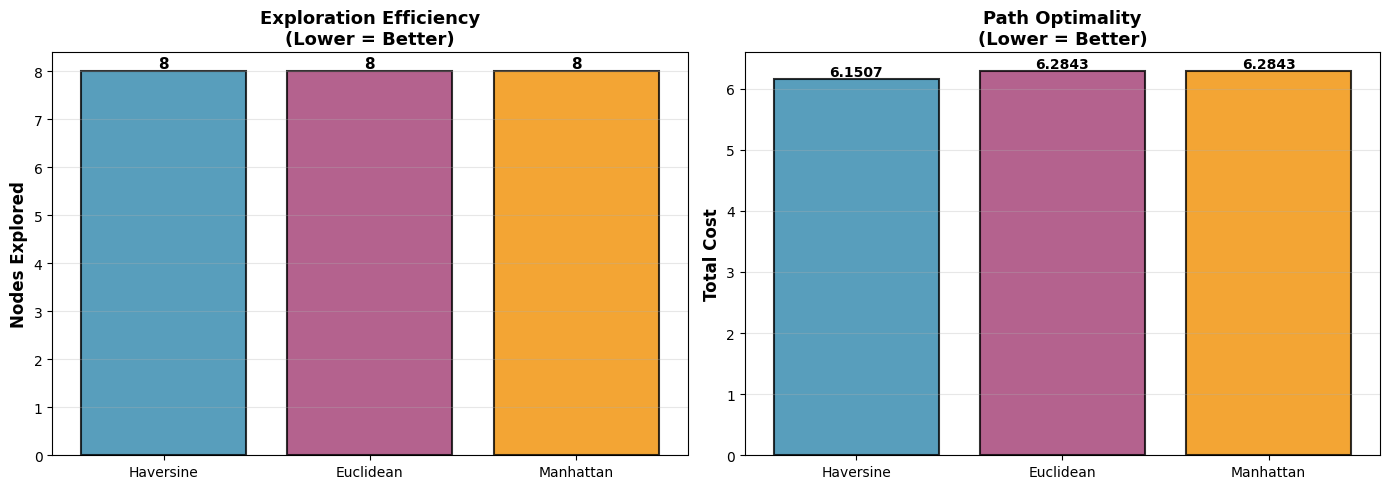

In [14]:
print("  Cost = alpha x pollution_score + (1 - alpha) x distance")
print("  Where:")
print("    - alpha = 0.7 (70% pollution weight, 30% distance weight)")
print("    - pollution_score = normalized 0-1 from PM10/PM2.5/NO2")
print("    - distance = Haversine distance in km")
print("    Lower cost = better route (less pollution + reasonable distance)\n")

heuristics = [
    ('Haversine', 'haversine', 'Admissible, optimal'),
    ('Euclidean', 'euclidean', 'Admissible, optimal'),
    ('Manhattan', 'manhattan', 'Admissible, optimal'),
]

# Test on first route for detailed comparison
test_route = test_routes[1]  # First route
print(f"Testing route: {test_route['name']}")
print(f"From {graph.nodes[test_route['start']]['name']} → {graph.nodes[test_route['goal']]['name']}\n")

astar_results = []

for h_name, h_type, h_desc in heuristics:
    algo = RoadNetworkAStarAlgorithm(graph, heuristic_type=h_type)
    result = algo.find_path(test_route['start'], test_route['goal'])
    
    if 'error' not in result:
        stats = algo.get_stats()
        path = result['path']

        # Calculate actual distance
        road_dist = 0
        for i in range(1, len(path)):
            from_node = graph.nodes[path[i-1]]
            to_node = graph.nodes[path[i]]
            road_dist += utils.haversine_distance(
                from_node['lat'], from_node['lon'],
                to_node['lat'], to_node['lon']
            )

        route_str = ' → '.join([graph.nodes[p]['name'].split()[0] for p in path[:4]])
        if len(path) > 4:
            route_str += '...'

        astar_results.append({
            'Heuristic': h_name,
            'Type': h_desc,
            'Nodes Explored': stats['nodes_explored'],
            'Stops': stats['path_length'],
            'Cost': f"{stats['total_cost']:.4f}",
            'Distance (km)': f"{road_dist:.2f}",
            'Route': route_str
        })
        
        print(f"{h_name:15s}")
        print(f"  Nodes explored: {stats['nodes_explored']:2d}")
        print(f"  Cost: {stats['total_cost']:.4f}")
        print(f"  Distance: {road_dist:.2f} km\n")

df_astar = pd.DataFrame(astar_results)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Extract data for plotting
heuristic_names = df_astar['Heuristic'].tolist()
nodes_explored = df_astar['Nodes Explored'].tolist()
costs = [float(c) for c in df_astar['Cost'].tolist()]

# Colors for each heuristic
colors = ['#2E86AB', '#A23B72', '#F18F01']  # Blue, Purple, Orange



# Left: Nodes Explored
bars1 = ax1.bar(heuristic_names, nodes_explored, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax1.set_ylabel('Nodes Explored', fontsize=12, fontweight='bold')
ax1.set_title('Exploration Efficiency\n(Lower = Better)', fontsize=13, fontweight='bold')
ax1.grid(True, axis='y', alpha=0.3)

# Add value labels on bars
for bar, value in zip(bars1, nodes_explored):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(value)}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')


# Right: Cost
bars2 = ax2.bar(heuristic_names, costs, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax2.set_ylabel('Total Cost', fontsize=12, fontweight='bold')
ax2.set_title('Path Optimality\n(Lower = Better)', fontsize=13, fontweight='bold')
ax2.grid(True, axis='y', alpha=0.3)

# Add value labels
for bar, value in zip(bars2, costs):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
            f'{value:.4f}',
            ha='center', va='bottom', fontsize=10, fontweight='bold')



plt.tight_layout()
plt.savefig('../images/heuristic_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# 7. Compare A* vs Dijkstra vs BFS

Algorithm Comparison: A* vs Dijkstra vs BFS

Running algorithms on all test routes...

Test 1: Clean North to South
  From: Herăstrău Park
  To: Berceni
  A* explored: 7 nodes
  Dijkstra explored: 18 nodes
  BFS explored: 18 nodes

Saved: ../images/comparison_test_1.png


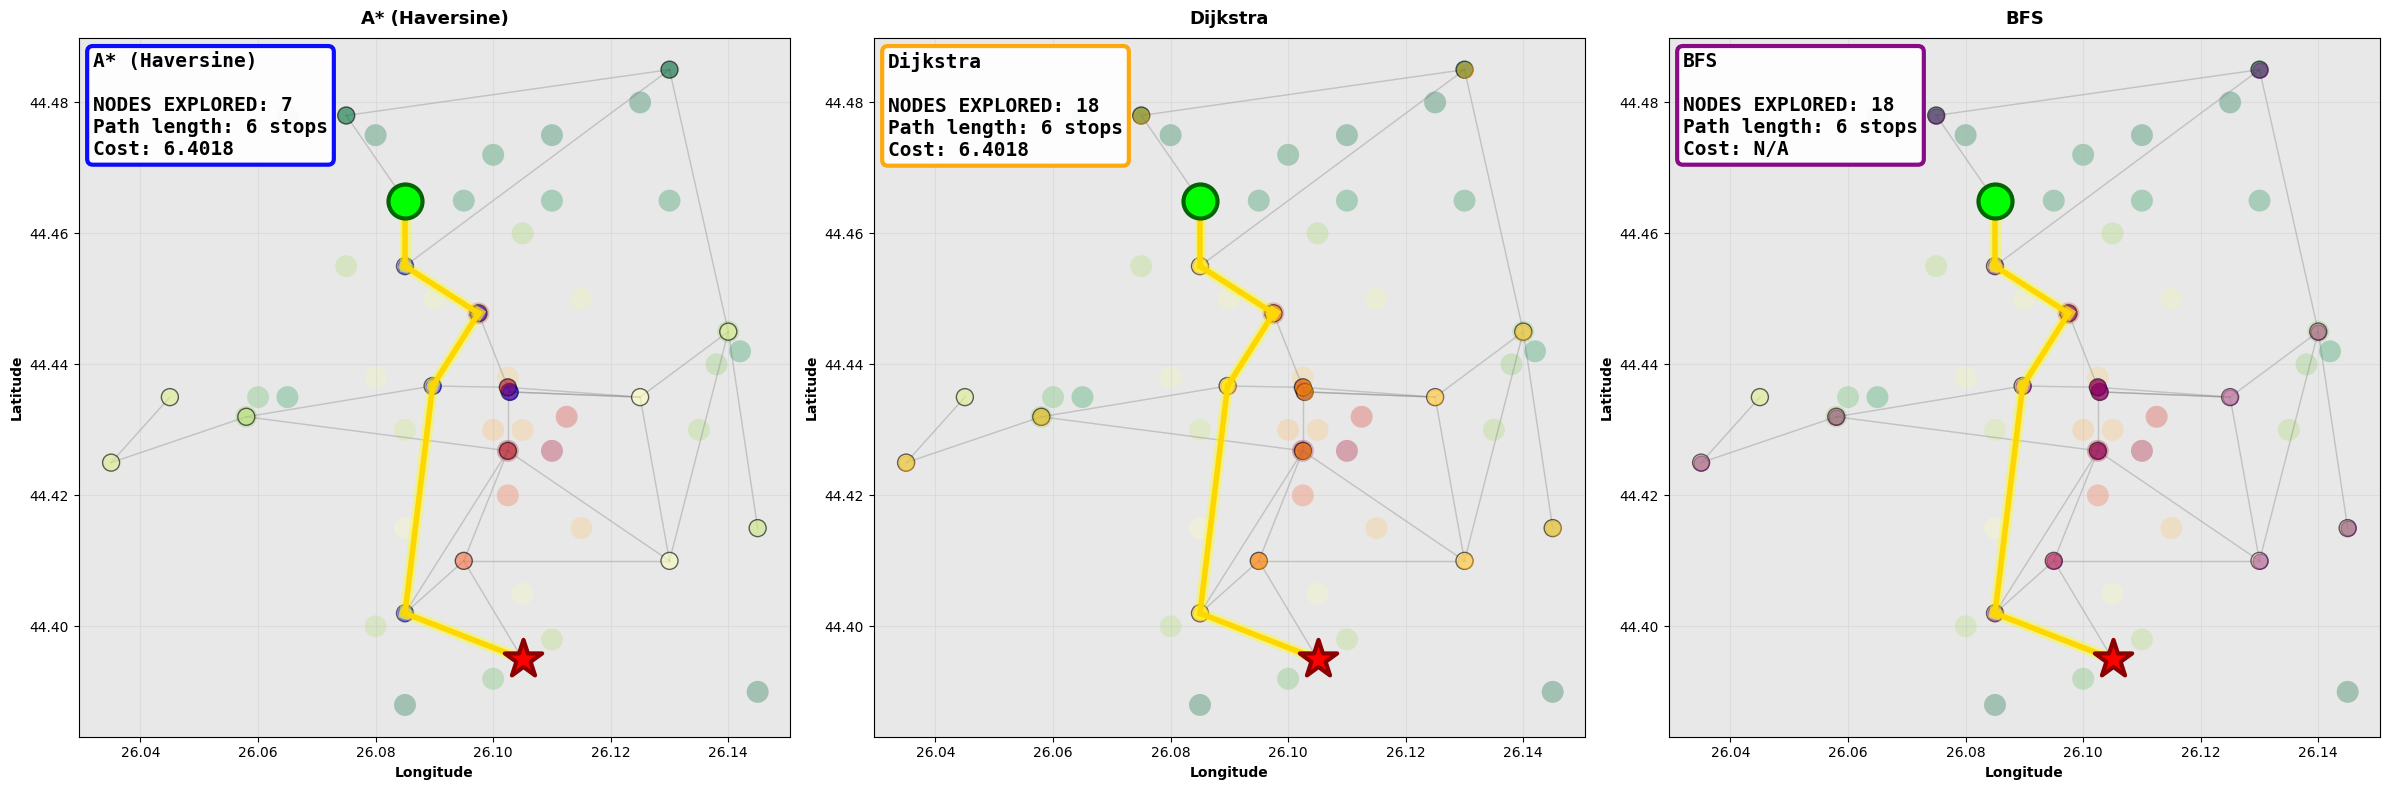

Test 2: Escape Pollution
  From: Piața Unirii
  To: Băneasa
  A* explored: 8 nodes
  Dijkstra explored: 19 nodes
  BFS explored: 18 nodes

Saved: ../images/comparison_test_2.png


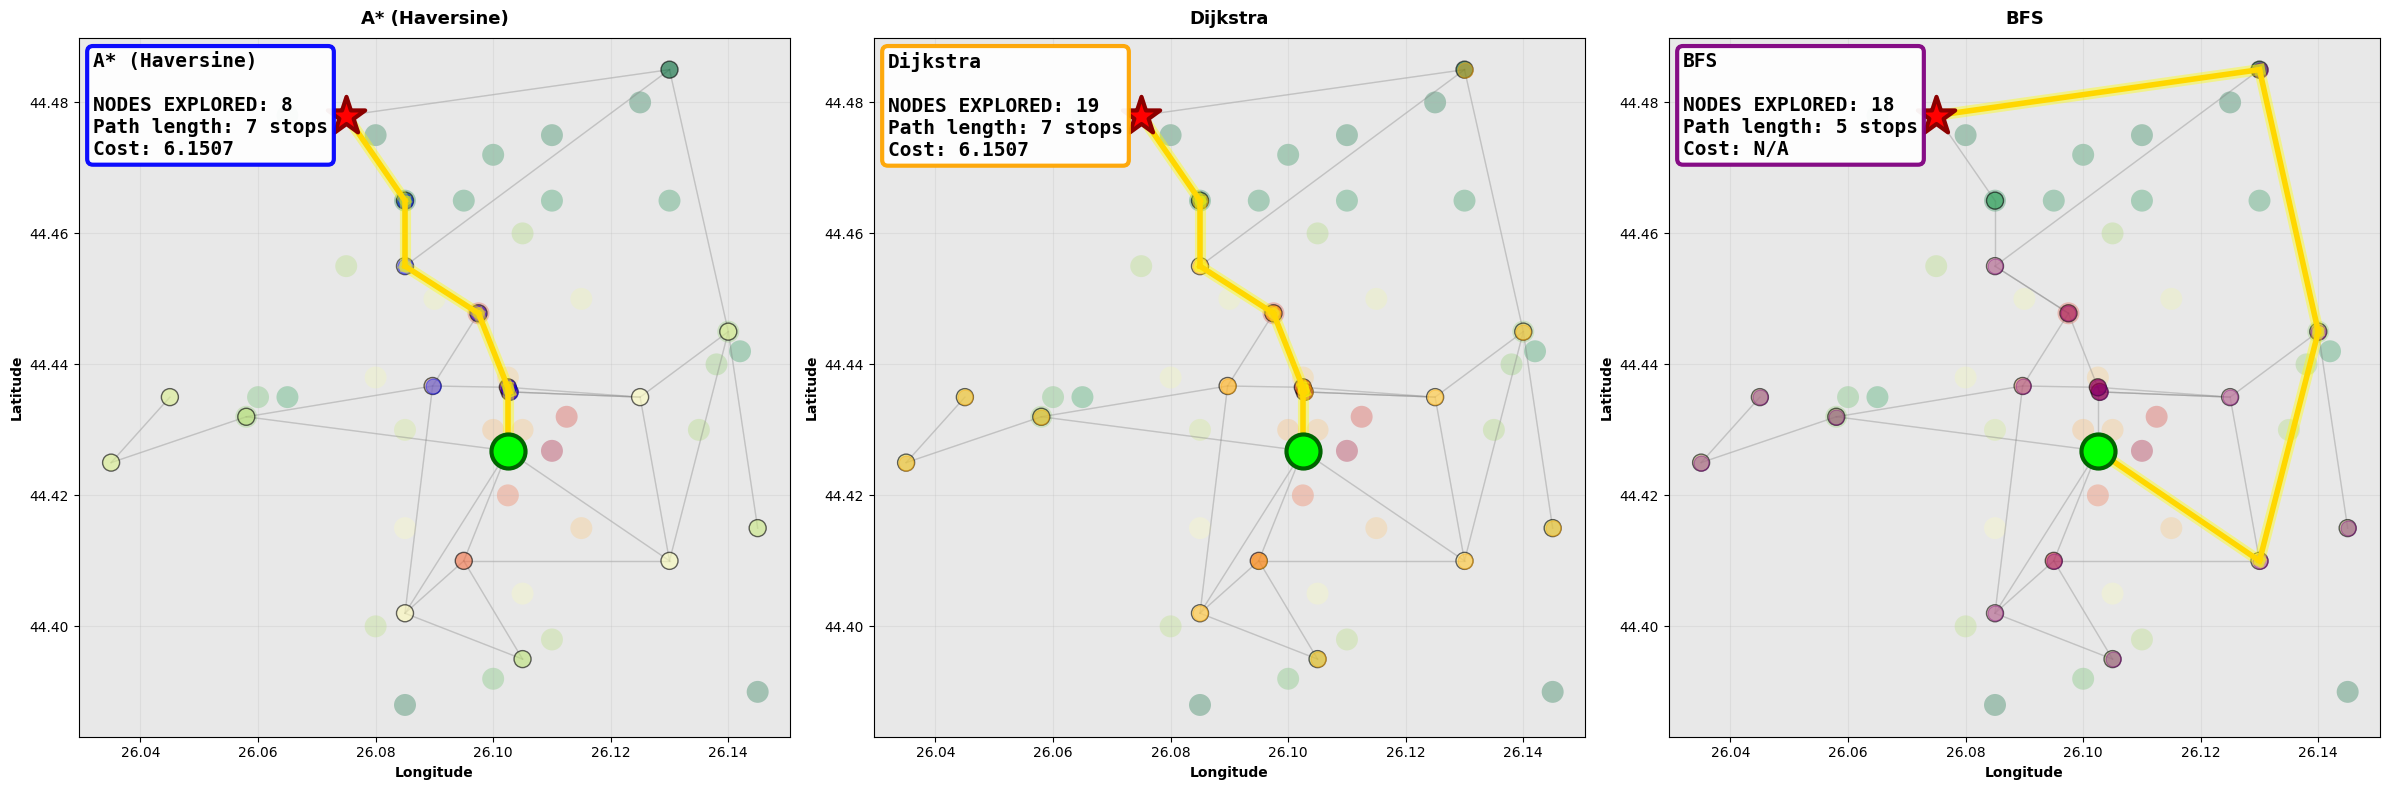

Test 3: Cross-City Commute
  From: Militari
  To: Pantelimon
  A* explored: 13 nodes
  Dijkstra explored: 19 nodes
  BFS explored: 18 nodes

Saved: ../images/comparison_test_3.png


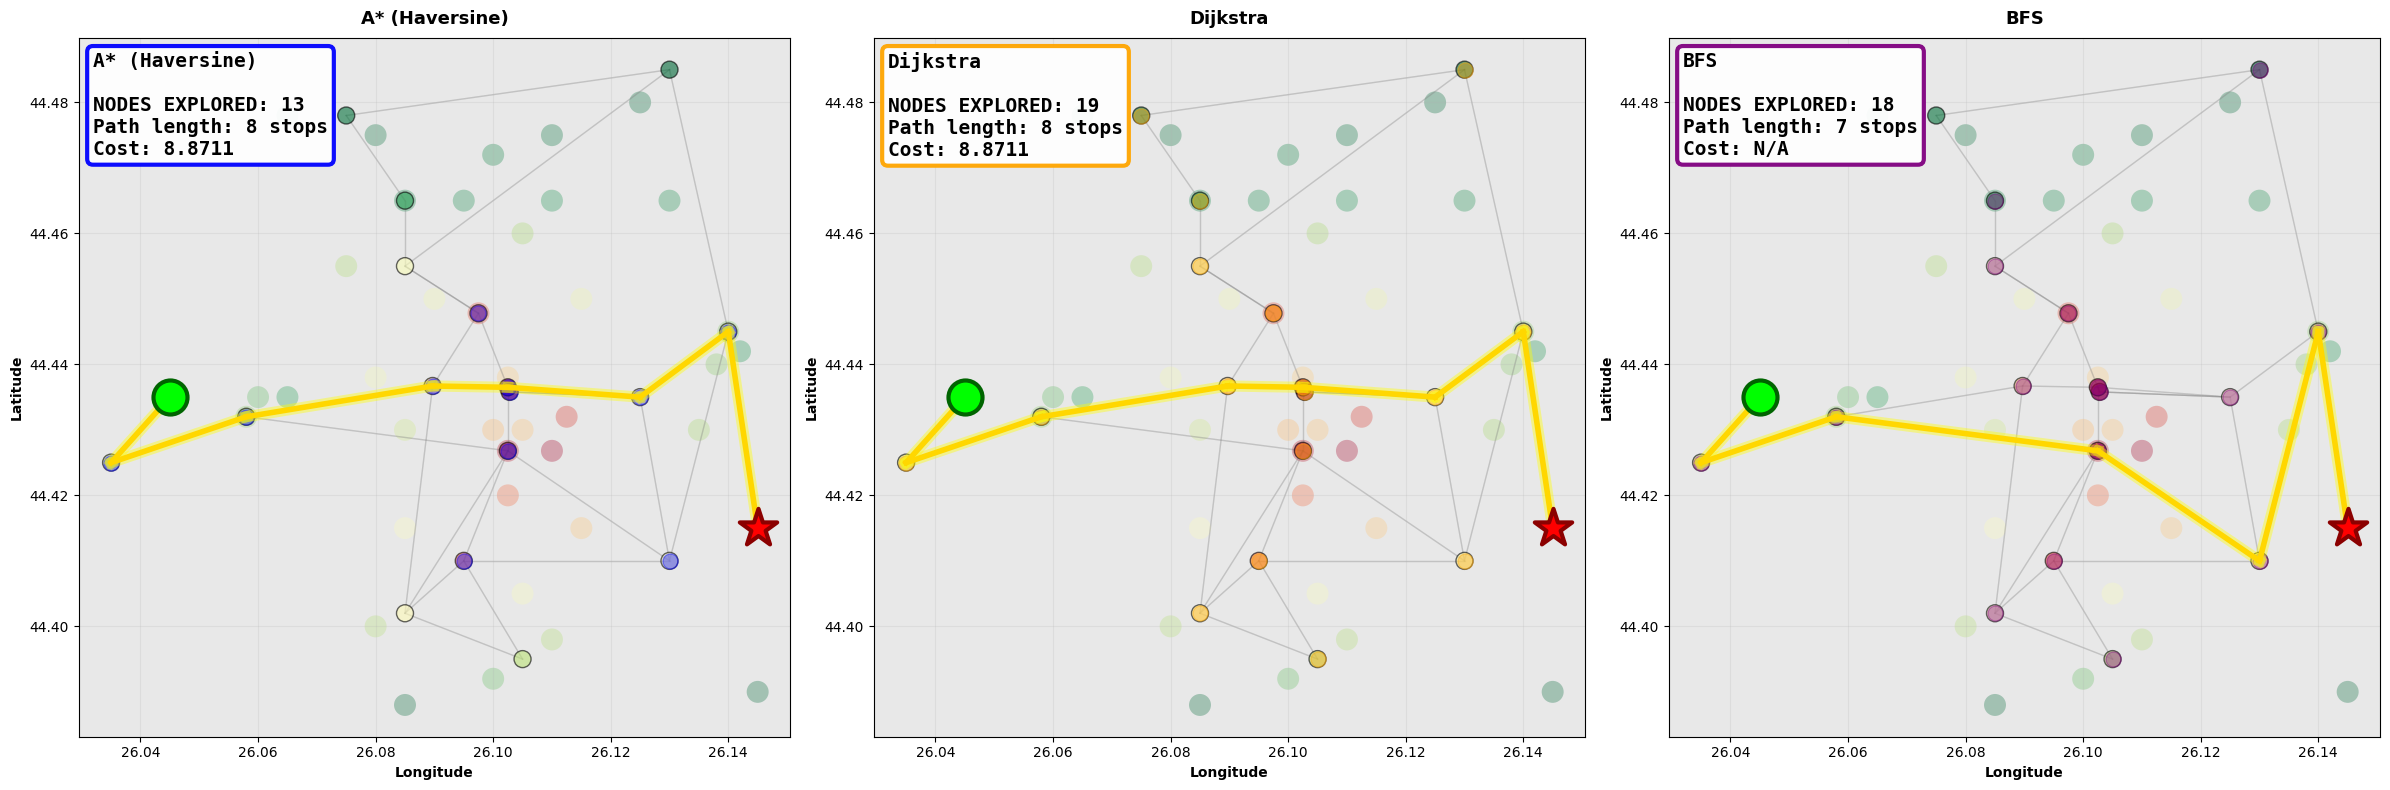

Test 4: Inner City Short
  From: Piața Romană
  To: Titan
  A* explored: 3 nodes
  Dijkstra explored: 9 nodes
  BFS explored: 9 nodes

Saved: ../images/comparison_test_4.png


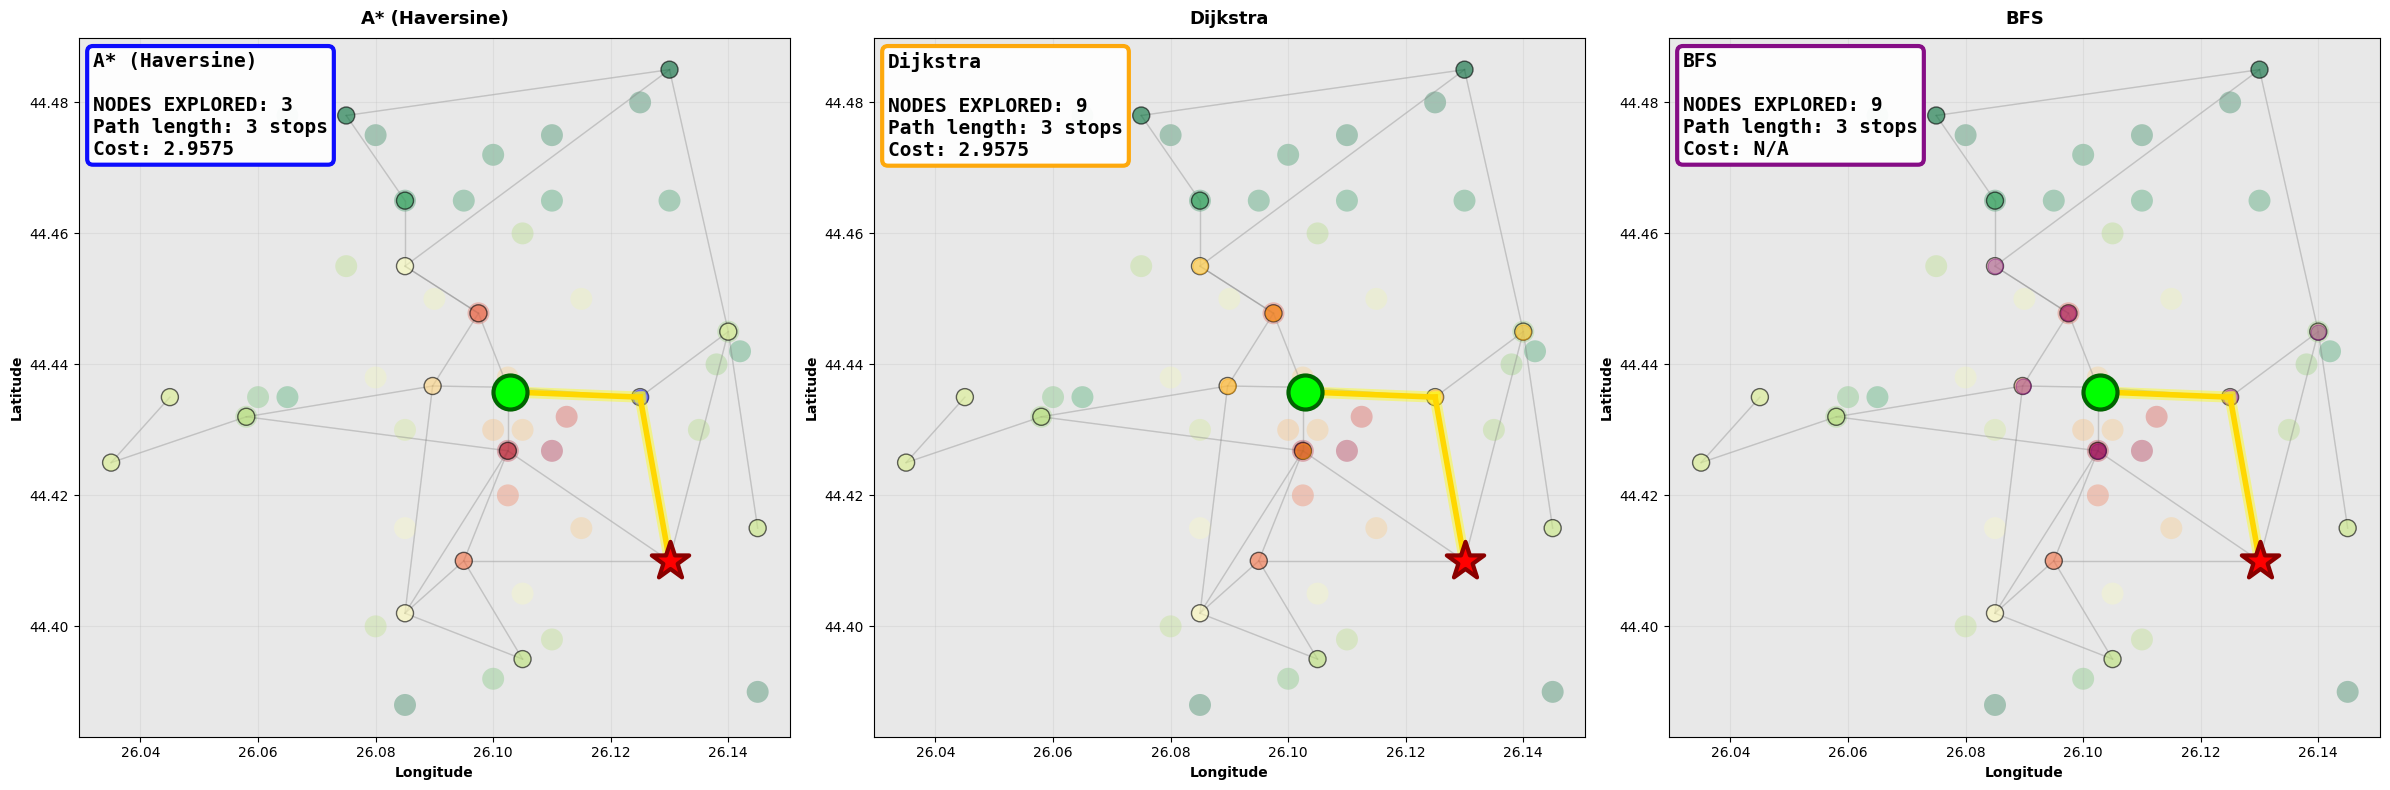

Test 5: Outer Ring
  From: Băneasa
  To: Pipera
  A* explored: 2 nodes
  Dijkstra explored: 3 nodes
  BFS explored: 3 nodes

Saved: ../images/comparison_test_5.png


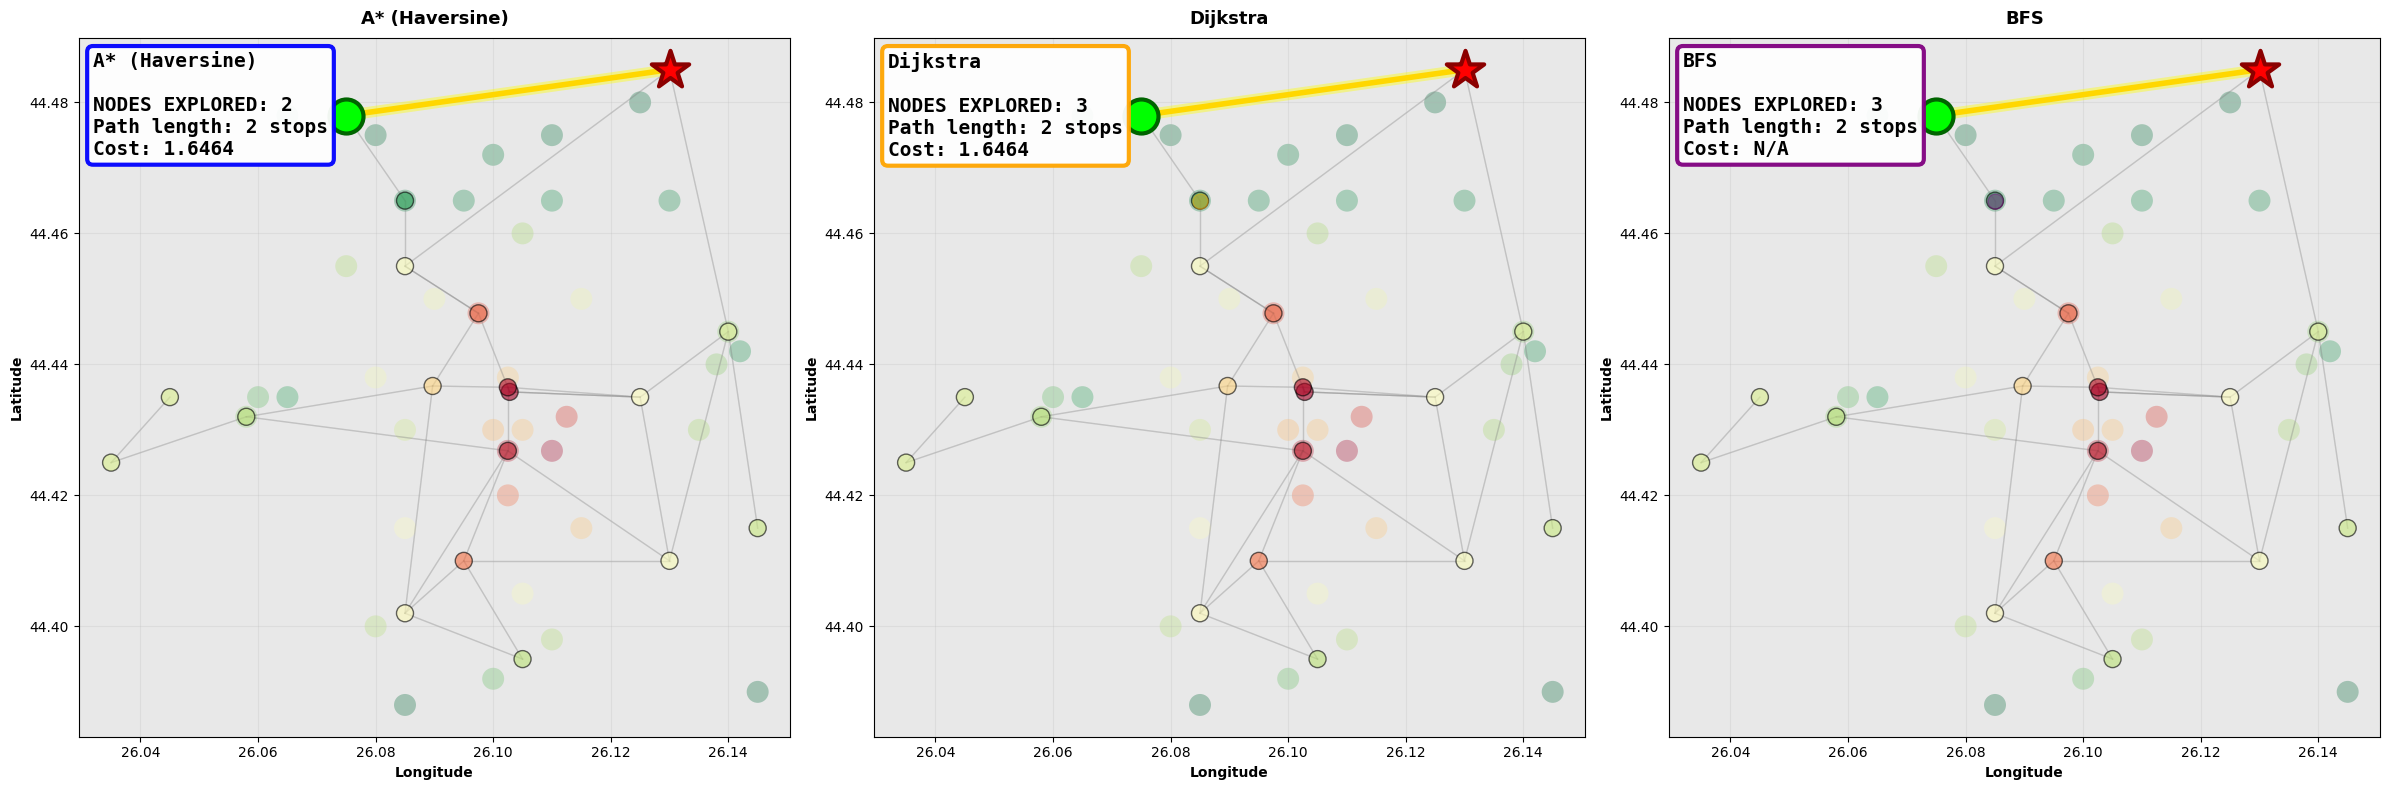

Test 6: Diagonal Traverse
  From: Cotroceni
  To: Colentina
  A* explored: 5 nodes
  Dijkstra explored: 16 nodes
  BFS explored: 15 nodes

Saved: ../images/comparison_test_6.png


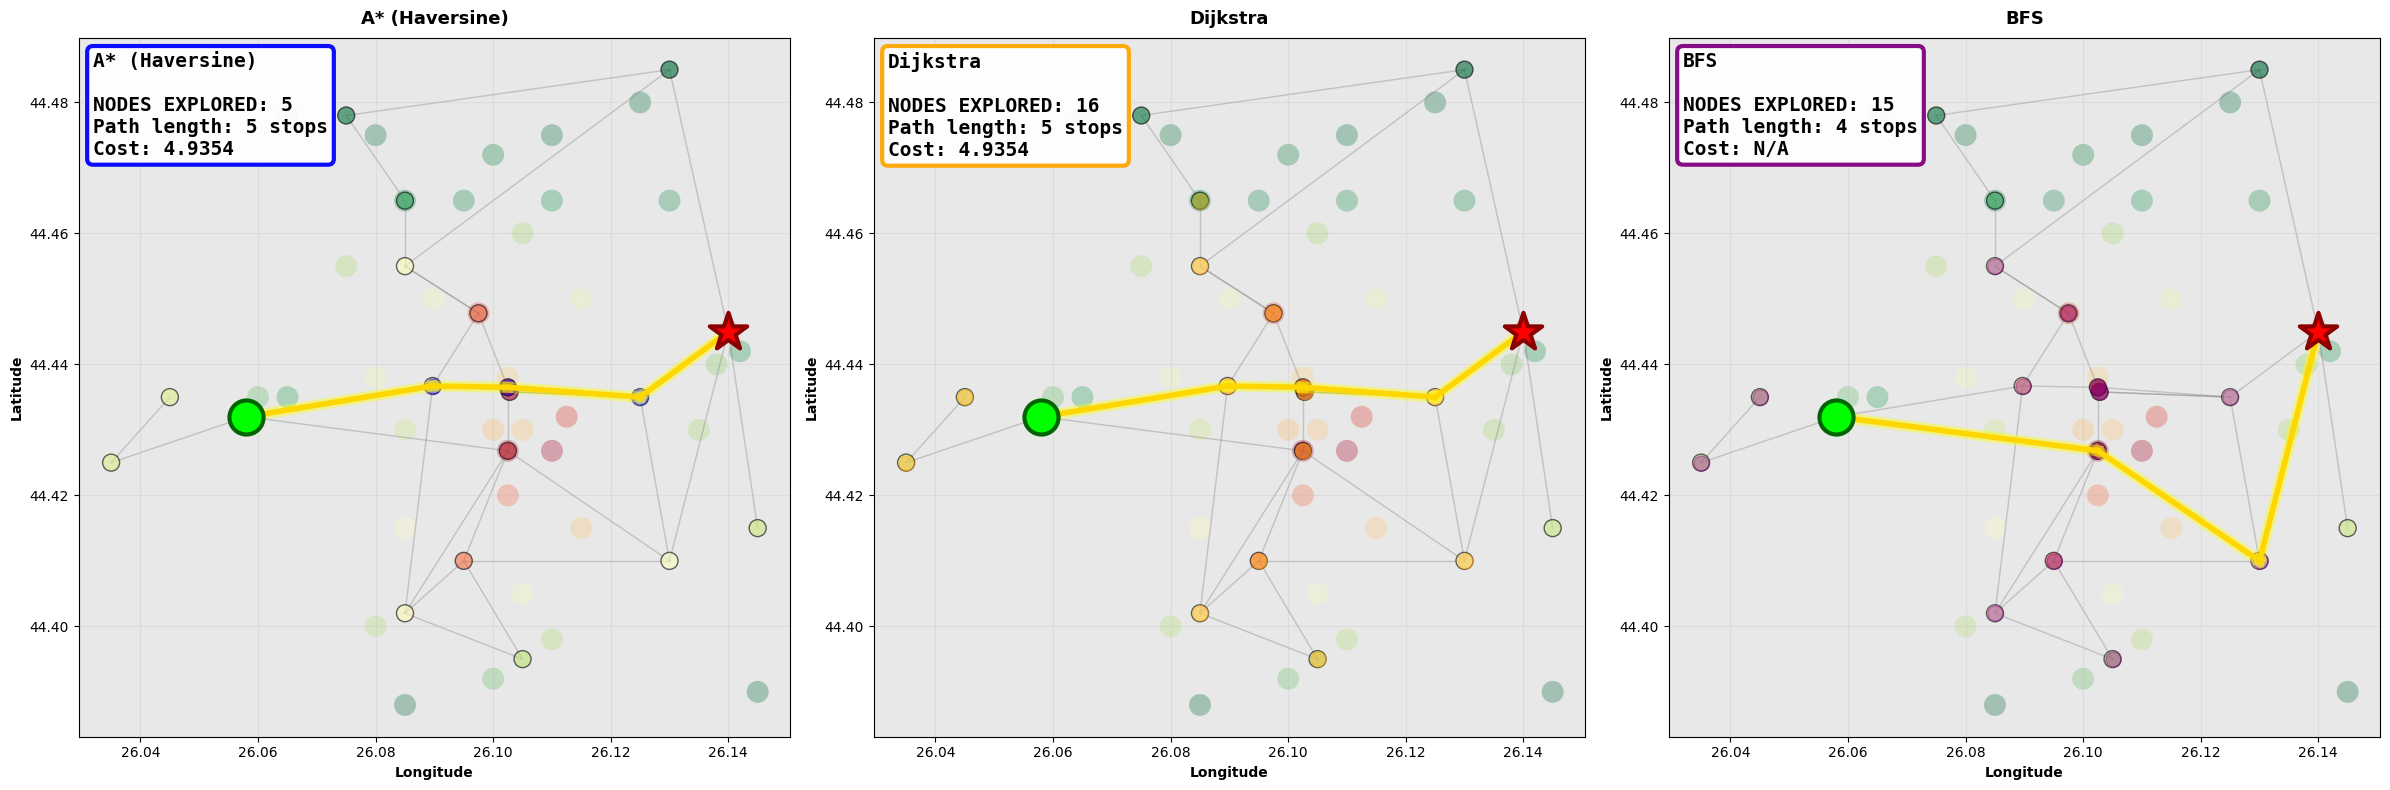


All comparisons complete.


In [15]:
# CELULA 7: Algorithm Comparison - Side-by-Side Visualization

print("Algorithm Comparison: A* vs Dijkstra vs BFS\n")

def visualize_algorithm_comparison(graph, test_route, astar_result, dijkstra_result, bfs_result, save_path=None):
    """
    Create side-by-side comparison of 3 algorithms for one test route.
    Shows final paths on map background with clear node count labels.
    """
    fig, axes = plt.subplots(1, 3, figsize=(24, 8))
    
    results = [
        ('A* (Haversine)', astar_result, 'blue'),
        ('Dijkstra', dijkstra_result, 'orange'),
        ('BFS', bfs_result, 'purple')
    ]
    
    # Load map background
    map_path = '../images/bucharest_base.png'
    map_loaded = False
    
    if os.path.exists(map_path):
        try:
            map_img = plt.imread(map_path)
            lat_min, lat_max = 44.35, 44.50
            lon_min, lon_max = 25.95, 26.20
            map_loaded = True
        except:
            pass
    
    # Sample pollution data for overlay
    sampled_data = bucharest_pollution_data[::3]
    pollution_lats = [d['lat'] for d in sampled_data]
    pollution_lons = [d['lon'] for d in sampled_data]
    pollution_scores = [
        d['pm10']/50.0*0.4 + d['pm25']/25.0*0.4 + d['no2']/40.0*0.2
        for d in sampled_data
    ]
    
    # All graph nodes
    all_lats = [n['lat'] for n in graph.nodes.values()]
    all_lons = [n['lon'] for n in graph.nodes.values()]
    all_pollution = [utils.calculate_pollution_score(**n['pollution']) 
                    for n in graph.nodes.values()]
    
    for idx, (algo_name, result, color) in enumerate(results):
        ax = axes[idx]
        
        if 'error' in result:
            ax.text(0.5, 0.5, f"Error: {result['error']}", 
                   ha='center', va='center', transform=ax.transAxes)
            continue
        
        # Map background
        if map_loaded:
            ax.imshow(map_img, extent=[lon_min, lon_max, lat_min, lat_max], 
                     aspect='auto', alpha=0.4, zorder=0)
        else:
            ax.set_facecolor('#e8e8e8')
        
        # Pollution overlay
        ax.scatter(pollution_lons, pollution_lats, c=pollution_scores,
                  cmap='RdYlGn_r', s=250, alpha=0.3, edgecolors='none', zorder=1)
        
        # All nodes (same size, colored by pollution)
        ax.scatter(all_lons, all_lats, c=all_pollution, cmap='RdYlGn_r',
                  s=150, alpha=0.6, edgecolors='black', linewidths=1, zorder=2)
        
        # Roads
        for int_id, neighbors in graph.edges.items():
            from_node = graph.nodes[int_id]
            for neighbor_id, _ in neighbors:
                to_node = graph.nodes[neighbor_id]
                ax.plot([from_node['lon'], to_node['lon']],
                       [from_node['lat'], to_node['lat']],
                       'gray', linewidth=1, alpha=0.2, zorder=1)
        
        # Explored nodes
        visited = result.get('visited_nodes', [])
        if visited:
            explored_ids = [v['node_id'] for v in visited]
            explored_lats = [graph.nodes[nid]['lat'] for nid in explored_ids]
            explored_lons = [graph.nodes[nid]['lon'] for nid in explored_ids]
            ax.scatter(explored_lons, explored_lats, c=color, s=120, alpha=0.4,
                      edgecolors=color, linewidths=1, zorder=3)
        
        # Final path
        path = result['path']
        for i in range(1, len(path)):
            from_node = graph.nodes[path[i-1]]
            to_node = graph.nodes[path[i]]
            
            ax.plot([from_node['lon'], to_node['lon']],
                   [from_node['lat'], to_node['lat']],
                   'yellow', linewidth=8, alpha=0.4, zorder=4)
            ax.plot([from_node['lon'], to_node['lon']],
                   [from_node['lat'], to_node['lat']],
                   'gold', linewidth=4, alpha=1.0, zorder=5)
        
        # Start & Goal
        start_node = graph.nodes[path[0]]
        goal_node = graph.nodes[path[-1]]
        
        ax.scatter([start_node['lon']], [start_node['lat']], 
                  c='lime', s=600, marker='o', edgecolors='darkgreen', 
                  linewidths=3, zorder=6)
        ax.scatter([goal_node['lon']], [goal_node['lat']], 
                  c='red', s=800, marker='*', edgecolors='darkred', 
                  linewidths=3, zorder=6)
        
        # Stats box with LARGE node count
        stats = result.get('stats', {})
        nodes_explored = stats.get('nodes_explored', len(visited))
        path_length = stats.get('path_length', len(path))
        
        stats_text = f"{algo_name}\n\n"
        stats_text += f"NODES EXPLORED: {nodes_explored}\n"
        stats_text += f"Path length: {path_length} stops\n"
        
        if stats.get('total_cost') is not None:
            stats_text += f"Cost: {stats['total_cost']:.4f}"
        else:
            stats_text += "Cost: N/A"
        
        ax.text(0.02, 0.98, stats_text,
               transform=ax.transAxes,
               fontsize=14,
               fontweight='bold',
               verticalalignment='top',
               family='monospace',
               bbox=dict(boxstyle='round', facecolor='white', 
                        alpha=0.95, edgecolor=color, linewidth=3),
               zorder=10)
        
        ax.set_xlabel('Longitude', fontsize=10, fontweight='bold')
        ax.set_ylabel('Latitude', fontsize=10, fontweight='bold')
        ax.set_title(algo_name, fontsize=13, fontweight='bold', pad=10)
        ax.grid(True, alpha=0.2)
    
    plt.tight_layout()
    
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()


# Run all 3 algorithms on each test route
print("Running algorithms on all test routes...\n")

for idx, test_route in enumerate(test_routes):
    print(f"Test {idx+1}: {test_route['name']}")
    print(f"  From: {graph.nodes[test_route['start']]['name']}")
    print(f"  To: {graph.nodes[test_route['goal']]['name']}")
    
    # Run A*
    astar_algo = RoadNetworkAStarAlgorithm(graph, heuristic_type='haversine')
    astar_result = astar_algo.find_path(test_route['start'], test_route['goal'])
    
    # Run Dijkstra
    dijkstra_algo = RoadNetworkDijkstraAlgorithm(graph)
    dijkstra_result = dijkstra_algo.find_path(test_route['start'], test_route['goal'])
    
    # Run BFS
    bfs_algo = RoadNetworkBFSAlgorithm(graph)
    bfs_result = bfs_algo.find_path(test_route['start'], test_route['goal'])
    
    # Quick stats
    if 'error' not in astar_result:
        astar_stats = astar_algo.get_stats()
        print(f"  A* explored: {astar_stats['nodes_explored']} nodes")
    
    if 'error' not in dijkstra_result:
        dijkstra_stats = dijkstra_algo.get_stats()
        print(f"  Dijkstra explored: {dijkstra_stats['nodes_explored']} nodes")
    
    if 'error' not in bfs_result:
        bfs_stats = bfs_algo.get_stats()
        print(f"  BFS explored: {bfs_stats['nodes_explored']} nodes")
    
    print()
    
    # Create comparison visualization
    save_path = f"../images/comparison_test_{idx+1}.png"
    visualize_algorithm_comparison(
        graph, test_route, 
        astar_result, dijkstra_result, bfs_result,
        save_path
    )

print("\nAll comparisons complete.")

# 8. Animations

In [16]:
# CELULA 8: Animations for All 3 Algorithms (Slower, More Nodes)

print("Creating animations for A*, Dijkstra, and BFS\n")

# Check ffmpeg
import subprocess
try:
    subprocess.run(['ffmpeg', '-version'], capture_output=True, check=True)
    ffmpeg_available = True
    print("ffmpeg is available")
except:
    print("ffmpeg not found - animations will be skipped")
    print("Install with: sudo apt-get install ffmpeg")
    ffmpeg_available = False

if ffmpeg_available:
    from matplotlib.animation import FuncAnimation, FFMpegWriter
    
    # Use first test route (should have most nodes)
    anim_route = test_routes[0]
    print(f"\nAnimating route: {anim_route['name']}")
    print(f"From: {graph.nodes[anim_route['start']]['name']}")
    print(f"To: {graph.nodes[anim_route['goal']]['name']}\n")
    
    # Run all 3 algorithms
    print("Running algorithms...")
    astar_anim = RoadNetworkAStarAlgorithm(graph, heuristic_type='haversine')
    astar_result = astar_anim.find_path(anim_route['start'], anim_route['goal'])
    
    dijkstra_anim = RoadNetworkDijkstraAlgorithm(graph)
    dijkstra_result = dijkstra_anim.find_path(anim_route['start'], anim_route['goal'])
    
    bfs_anim = RoadNetworkBFSAlgorithm(graph)
    bfs_result = bfs_anim.find_path(anim_route['start'], anim_route['goal'])
    
    print(f"A* will explore: {len(astar_result['visited_nodes'])} nodes")
    print(f"Dijkstra will explore: {len(dijkstra_result['visited_nodes'])} nodes")
    print(f"BFS will explore: {len(bfs_result['visited_nodes'])} nodes\n")
    
    # Animation configuration
    map_path = '../images/bucharest_base.png'
    map_loaded = False
    
    if os.path.exists(map_path):
        try:
            map_img = plt.imread(map_path)
            lat_min, lat_max = 44.35, 44.50
            lon_min, lon_max = 25.95, 26.20
            map_loaded = True
        except:
            pass
    
    # Prepare pollution overlay
    sampled_data = bucharest_pollution_data[::3]
    pollution_lats = [d['lat'] for d in sampled_data]
    pollution_lons = [d['lon'] for d in sampled_data]
    pollution_scores = [
        d['pm10']/50.0*0.4 + d['pm25']/25.0*0.4 + d['no2']/40.0*0.2
        for d in sampled_data
    ]
    
    # All graph nodes
    all_lats = [n['lat'] for n in graph.nodes.values()]
    all_lons = [n['lon'] for n in graph.nodes.values()]
    all_pollution = [utils.calculate_pollution_score(**n['pollution']) 
                    for n in graph.nodes.values()]
    
    # Start & Goal nodes
    start_node = graph.nodes[anim_route['start']]
    goal_node = graph.nodes[anim_route['goal']]
    
    
    def create_animation(result, algo_name, color, output_path):
        """Create animation for one algorithm."""
        if 'error' in result:
            print(f"Error in {algo_name}: {result['error']}")
            return
        
        visited_nodes = result['visited_nodes']
        final_path = result['path']
        
        print(f"Creating {algo_name} animation ({len(visited_nodes)} frames)...")
        
        fig, (ax_map, ax_cost) = plt.subplots(1, 2, figsize=(20, 10))
        
        # Left: Map
        if map_loaded:
            ax_map.imshow(map_img, extent=[lon_min, lon_max, lat_min, lat_max], 
                         aspect='auto', alpha=0.4, zorder=0)
        else:
            ax_map.set_facecolor('#e8e8e8')
        
        # Pollution overlay
        ax_map.scatter(pollution_lons, pollution_lats, c=pollution_scores,
                      cmap='RdYlGn_r', s=250, alpha=0.3, edgecolors='none', zorder=1)
        
        # All nodes
        ax_map.scatter(all_lons, all_lats, c=all_pollution, cmap='RdYlGn_r',
                      s=150, alpha=0.6, edgecolors='black', linewidths=1, zorder=2)
        
        # Roads
        for int_id, neighbors in graph.edges.items():
            from_node = graph.nodes[int_id]
            for neighbor_id, _ in neighbors:
                to_node = graph.nodes[neighbor_id]
                ax_map.plot([from_node['lon'], to_node['lon']],
                          [from_node['lat'], to_node['lat']],
                          'gray', linewidth=1, alpha=0.2, zorder=1)
        
        # Start & Goal
        ax_map.scatter([start_node['lon']], [start_node['lat']], 
                      c='lime', s=600, marker='o', edgecolors='darkgreen', 
                      linewidths=3, zorder=7, label='START')
        ax_map.scatter([goal_node['lon']], [goal_node['lat']], 
                      c='red', s=800, marker='*', edgecolors='darkred', 
                      linewidths=3, zorder=7, label='GOAL')
        
        # Animation elements
        explored_scatter = ax_map.scatter([], [], c=color, s=100, alpha=0.5, 
                                         edgecolors=color, linewidths=1, 
                                         zorder=4, label='Explored')
        current_marker = ax_map.scatter([], [], c=color, s=250, marker='o',
                                       edgecolors='white', linewidths=2,
                                       zorder=6, label='Current')
        
        ax_map.set_xlabel('Longitude', fontsize=10, fontweight='bold')
        ax_map.set_ylabel('Latitude', fontsize=10, fontweight='bold')
        ax_map.set_title(f'{algo_name} Exploration', fontsize=12, fontweight='bold')
        ax_map.legend(loc='upper right', fontsize=9)
        ax_map.grid(True, alpha=0.2)
        
        # Right: Cost evolution
        g_scores = []
        
        # Label depends on algorithm
        if algo_name == 'BFS':
            y_label = 'Nodes Visited'
            title_label = f'{algo_name} Progress'
        else:
            y_label = 'Cost'
            title_label = f'{algo_name} Cost Evolution'
        
        ax_cost.set_xlabel('Nodes Explored', fontsize=10, fontweight='bold')
        ax_cost.set_ylabel(y_label, fontsize=10, fontweight='bold')
        ax_cost.set_title(title_label, fontsize=12, fontweight='bold')
        ax_cost.grid(True, alpha=0.3)
        
        g_line, = ax_cost.plot([], [], color=color, linewidth=2, label='g(n)' if algo_name != 'BFS' else 'Progress')
        ax_cost.legend(loc='upper left', fontsize=10)
        
        # Large node counter
        nodes_text = ax_cost.text(
            0.98, 0.98, '',
            transform=ax_cost.transAxes,
            fontsize=22,
            fontweight='bold',
            verticalalignment='top',
            horizontalalignment='right',
            color=color,
            bbox=dict(boxstyle='round', facecolor='white', 
                     alpha=0.9, edgecolor=color, linewidth=2)
        )
        
        def init():
            explored_scatter.set_offsets(np.empty((0, 2)))
            current_marker.set_offsets(np.empty((0, 2)))
            g_line.set_data([], [])
            nodes_text.set_text('')
            return explored_scatter, current_marker, g_line, nodes_text
        
        def animate(frame):
            # Update explored nodes
            explored_so_far = visited_nodes[:frame+1]
            explored_ids = [v['node_id'] for v in explored_so_far]
            explored_lats = [graph.nodes[nid]['lat'] for nid in explored_ids]
            explored_lons = [graph.nodes[nid]['lon'] for nid in explored_ids]
            explored_scatter.set_offsets(np.column_stack([explored_lons, explored_lats]))
            
            # Current node
            current_id = visited_nodes[frame]['node_id']
            current_node = graph.nodes[current_id]
            current_marker.set_offsets([[current_node['lon'], current_node['lat']]])
            
            # Update cost (BFS doesn't have g_score, use frame number)
            if 'g_score' in visited_nodes[frame]:
                g_scores.append(visited_nodes[frame]['g_score'])
            else:
                g_scores.append(frame)  # BFS: just use frame count
            
            g_line.set_data(range(len(g_scores)), g_scores)
            
            ax_cost.set_xlim(0, max(len(visited_nodes), 10))
            ax_cost.set_ylim(0, max(g_scores) * 1.1 if g_scores else 1)
            
            # Update counter
            nodes_text.set_text(f'{algo_name}\n{frame+1}/{len(visited_nodes)}')
            
            # Draw final path
            if frame == len(visited_nodes) - 1:
                for i in range(1, len(final_path)):
                    from_n = graph.nodes[final_path[i-1]]
                    to_n = graph.nodes[final_path[i]]
                    ax_map.plot([from_n['lon'], to_n['lon']],
                              [from_n['lat'], to_n['lat']],
                              'gold', linewidth=4, alpha=0.9, zorder=5)
            
            return explored_scatter, current_marker, g_line, nodes_text
        
        # Create animation - SLOWER: 250ms per frame instead of 150ms
        anim = FuncAnimation(
            fig, animate, init_func=init,
            frames=len(visited_nodes),
            interval=250,  # Slower animation
            blit=True,
            repeat=False
        )
        
        # Save
        os.makedirs(os.path.dirname(output_path), exist_ok=True)
        print(f"Saving to {output_path}...")
        writer = FFMpegWriter(fps=8, bitrate=2000)  # 8 fps instead of 10
        anim.save(output_path, writer=writer)
        
        print(f"Saved: {output_path}")
        print(f"Duration: {len(visited_nodes)/8:.1f} seconds\n")
        
        plt.close(fig)
    
    
    # Create all 3 animations
    create_animation(astar_result, 'A*', 'blue', '../images/astar_animation.mp4')
    create_animation(dijkstra_result, 'Dijkstra', 'orange', '../images/dijkstra_animation.mp4')
    create_animation(bfs_result, 'BFS', 'purple', '../images/bfs_animation.mp4')
    
    print("\nAnimation Summary:")
    print(f"A* explored: {len(astar_result['visited_nodes'])} nodes")
    print(f"Dijkstra explored: {len(dijkstra_result['visited_nodes'])} nodes")
    print(f"BFS explored: {len(bfs_result['visited_nodes'])} nodes")
    print(f"\nDijkstra explores {len(dijkstra_result['visited_nodes']) / len(astar_result['visited_nodes']):.1f}x more nodes than A*")
    print(f"BFS explores {len(bfs_result['visited_nodes']) / len(astar_result['visited_nodes']):.1f}x more nodes than A*")

else:
    print("\nSkipping animations (ffmpeg not available)")

Creating animations for A*, Dijkstra, and BFS

ffmpeg is available

Animating route: Clean North to South
From: Herăstrău Park
To: Berceni

Running algorithms...
A* will explore: 7 nodes
Dijkstra will explore: 18 nodes
BFS will explore: 18 nodes

Creating A* animation (7 frames)...
Saving to ../images/astar_animation.mp4...


/tmp/ipykernel_27346/2066719486.py:193: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax_cost.set_ylim(0, max(g_scores) * 1.1 if g_scores else 1)


Saved: ../images/astar_animation.mp4
Duration: 0.9 seconds

Creating Dijkstra animation (18 frames)...
Saving to ../images/dijkstra_animation.mp4...


/tmp/ipykernel_27346/2066719486.py:193: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax_cost.set_ylim(0, max(g_scores) * 1.1 if g_scores else 1)


Saved: ../images/dijkstra_animation.mp4
Duration: 2.2 seconds

Creating BFS animation (18 frames)...
Saving to ../images/bfs_animation.mp4...


/tmp/ipykernel_27346/2066719486.py:193: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax_cost.set_ylim(0, max(g_scores) * 1.1 if g_scores else 1)


Saved: ../images/bfs_animation.mp4
Duration: 2.2 seconds


Animation Summary:
A* explored: 7 nodes
Dijkstra explored: 18 nodes
BFS explored: 18 nodes

Dijkstra explores 2.6x more nodes than A*
BFS explores 2.6x more nodes than A*
